# Quick and dirty nb for examnining data from initial courtship test

## Imports

In [20]:
import os
import glob

import numpy as np
from matplotlib import rcParams
import matplotlib.pyplot as plt

from scipy import signal 
from pathlib import Path
from mosquito.process_abf import my_load_abf, filter_microphone

## Plots params

In [21]:
# PLOT PARAMETERS
plot_type = 'powerpoint'  # 'paper' or 'powerpoint'

# # generate a dictionary called fig params that encodes information we care about
if plot_type == 'powerpoint':
    fontsize = 14
    figsize = (10,7.5)
    subplot_left = 0.15
    subplot_right = 0.85
    subplot_top = 0.8
    subplot_bottom = 0.15
elif plot_type == 'paper':
    fontsize = 8
    figsize = (8,8)
    subplot_left = 0.2
    subplot_right = 0.8
    subplot_top = 0.8
    subplot_bottom = 0.2

fig_params = {
      'font.family' : 'sans-serif',
      'font.serif' : 'Times, Palatino, New Century Schoolbook, Bookman, Computer Modern Roman',
      'font.sans-serif' : 'arial, Helvetica, Avant Garde, Computer Modern Sans serif',
      'font.cursive' : 'Zapf Chancery',
      'font.monospace' : 'Courier, Computer Modern Typewriter',
      'font.size' : fontsize,
      'axes.labelsize': fontsize,
      'axes.linewidth': 1.0,
      'xtick.major.width': 1,
      'xtick.minor.width': 1,
      'xtick.labelsize': fontsize,
      'ytick.labelsize': fontsize,
      'figure.figsize': figsize,
}
rcParams.update(fig_params) 

## Load data

In [22]:
# get path to data
root_path =  Path(r"C:\Users\whitehead.262\OneDrive - The Ohio State University\mosquito_ephys\mosquito-data")
expr_folder = "106_20260722"
axo_num = 0

subfolder_str = "*_{:04d}"  
ext = ".abf"

# find path to data file, given info
search_path = root_path / expr_folder / subfolder_str.format(axo_num)
search_results = glob.glob(str(search_path / f'*{ext}'))

# check that we can find a unique matching file
if len(search_results) != 1:
    raise ValueError('Could not locate file in {}'.format(search_path))

data_path_full = search_results[0]
print(data_path_full)

C:\Users\whitehead.262\OneDrive - The Ohio State University\mosquito_ephys\mosquito-data\106_20260722\2026_07_22_0000\2026_07_22_0000.abf


In [23]:
# load abf 
abf_dict = my_load_abf(data_path_full)

## Visualize spectrogram

In [24]:
# read out the data
for key in abf_dict.keys():
    print(key)

sampling_freq
filepath
units
header
time
emg
mic


In [25]:
# params for calculation
NPERSEG = 16384 
MAX_WBF = 1750
MIN_WBF = 200

MIC_LOWCUT = MIN_WBF
MIC_HIGHCUT = MAX_WBF

fs = abf_dict['sampling_freq']

In [26]:
# filter microphone
mic_filt = filter_microphone(abf_dict['mic'], fs, lowcut=MIC_LOWCUT, highcut=MIC_HIGHCUT)

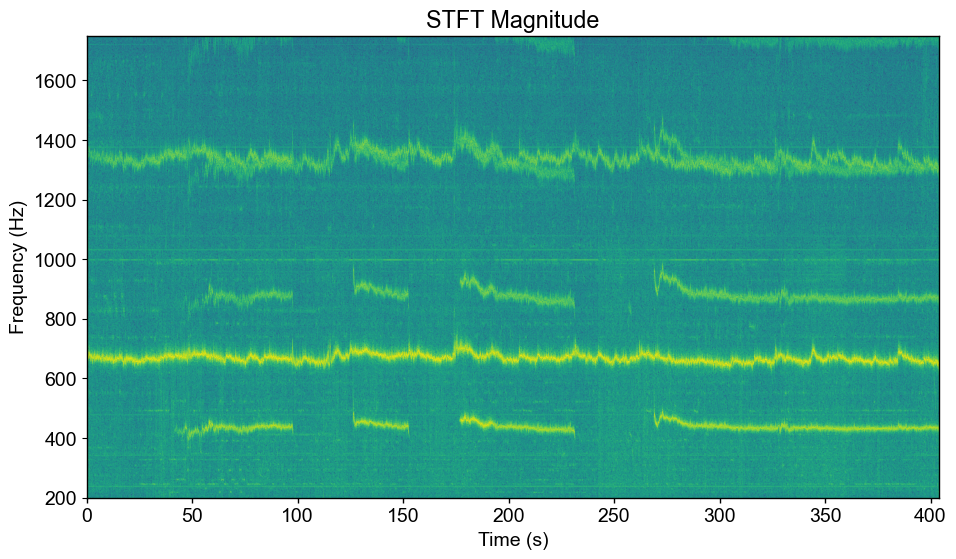

In [27]:
# calculate short term fourier transform
freq, t, Zxx = signal.stft(mic_filt, fs, nperseg=NPERSEG)

# # restrict attention to frequencies < max_freq
if MAX_WBF is not None:
    keep_idx = (freq <= MAX_WBF)
    freq = freq[keep_idx]
    Zxx = Zxx[keep_idx, :]

if MIN_WBF is not None:
    keep_idx = (freq >= MIN_WBF)
    freq = freq[keep_idx]
    Zxx = Zxx[keep_idx, :]
    
# # get max vals at each time point
# freq_max_idx = np.argmax(np.abs(Zxx), axis=0)
# freq_max = freq[freq_max_idx]

# # upsample estimated wbf to full time range
# t_full = (1 / abf_dict['sampling_freq']) * np.arange(abf_dict['mic'].size)
# wbf = np.interp(t_full, t, freq_max)

# make figure
fig, ax = plt.subplots(figsize=(11, 6))

# plot data
ax.pcolormesh(t, freq, np.abs(Zxx), shading='gouraud', norm='log')  # , cmap = plt.colormaps["plasma"])
# ax.plot(t_full, wbf, 'r-')

ax.set_ylim([MIC_LOWCUT, MIC_HIGHCUT])
# label axes
ax.set_title('STFT Magnitude')
ax.set_ylabel('Frequency (Hz)')
ax.set_xlabel('Time (s)')

plt.show()
fig.savefig(r"C:\Users\whitehead.262\OneDrive - The Ohio State University\mosquito_ephys\plots_temp\expr106_axo0000_spectrogram.png")

In [56]:
# f, t, Sxx = signal.spectrogram(mic_filt, fs)


In [75]:
# fig = plt.figure(figsize=(8,8))
# cmap = plt.colormaps["plasma"]
# plt.pcolormesh(t, f, Sxx, shading='gouraud', cmap=cmap, norm='log')
# plt.ylabel('Frequency [Hz]')
# plt.xlabel('Time [sec]')
# plt.ylim([0, MIC_HIGHCUT])
# plt.show()

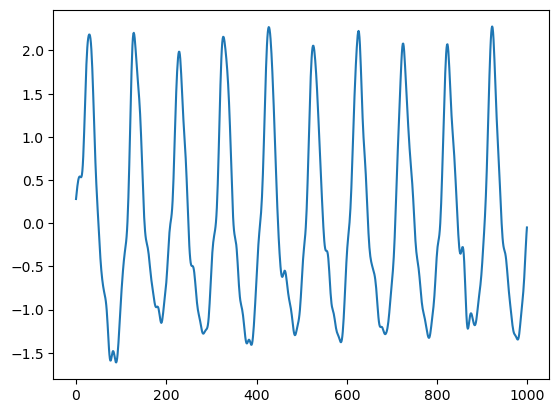

In [35]:
plt.plot(mic_filt[:1000])